# Blood Cell Classification: A BatchNorm CNN from Scratch

**Competition:** Fall 26 Deep Learning, BloodMNIST-style 28x28 RGB cells, 8 classes. **Pretrained weights: none** (everything is trained from random init).

This notebook applies the tutorials directly:

| Tutorial | What we reuse here |
| :--- | :--- |
| **2: CNN** | Modular `ConvBlock` design, `3x3` conv with `padding=1`, `MaxPool2d`, Global Average Pooling head, the *overfit-a-tiny-subset* sanity check, `train_one_epoch` / `evaluate` structure |
| **3: BatchNorm** | `Conv -> BatchNorm -> ReLU` ordering, `bias=False` before BN, `model.eval()` for inference (running statistics), higher learning rate tolerance |
| **4: Dropout** | `CustomDropout` (inverted dropout, written from scratch), light dropout in conv layers and heavier dropout in the dense head only |

**Pipeline:** load data -> stratified train/val split -> GPU augmentation -> BatchNorm CNN -> sanity check -> train (best-val checkpoint) -> small seed ensemble + test-time augmentation -> `submission.csv`.

## 1. Setup & Reproducibility

In [1]:
import os, glob, math, time, copy, random, zipfile
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

SEED = 42
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch version: {torch.__version__}")
print(f"Compute device:  {device}")

PyTorch version: 2.11.0+cu128
Compute device:  cuda


## 2. Configuration
All hyperparameters live in one place so the notebook can be re-run and verified easily.

In [2]:
CFG = dict(
    val_fraction = 0.10,       # 10% validation set for model selection
    batch_size   = 64,          # smaller batches are more stable and easier to debug
    epochs       = 50,          # more updates usually improve final accuracy
    max_lr       = 4e-3,        # a strong peak LR works well with BatchNorm
    weight_decay = 5e-4,        # mild regularization
    label_smooth = 0.05,        # prevents overconfident predictions
    widths       = (64, 128, 256),
    conv_drop    = 0.08,        # light dropout inside convolution stages
    head_drop    = 0.35,        # slightly lower than before to preserve signal
    n_models     = 3,           # ensemble of 3 models with different seeds
)
NUM_CLASSES = 8
CLASS_NAMES = ['basophil', 'eosinophil', 'erythroblast', 'immature gran.',
               'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


## 3. Load the Data
The cell below finds the competition files automatically, whether you run on **Kaggle** (`/kaggle/input/...`) or locally (put `train.csv`, `train/`, `test/`, `sample_submission.csv` next to the notebook; `train.zip` / `test.zip` are extracted automatically if needed).

In [3]:
def find_data_dir():
    candidates = ['/kaggle/input/fcds-au-fall-26-deep-learning-assignment',
                  '/kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment',
                  '.', './data']
    for c in candidates:
        if os.path.exists(os.path.join(c, 'train.csv')):
            return c
    for base in ['/kaggle/input', '.']:
        hits = glob.glob(os.path.join(base, '**', 'train.csv'), recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("train.csv not found. Attach the competition data or place the files next to this notebook.")

def get_image_dir(root, name):
    d = os.path.join(root, name)
    if os.path.isdir(d):
        return d
    z = os.path.join(root, name + '.zip')
    if os.path.exists(z):
        out = os.path.join('extracted', name)
        if not os.path.isdir(out):
            os.makedirs(out, exist_ok=True)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(out)
        inner = os.path.join(out, name)
        return inner if os.path.isdir(inner) else out
    raise FileNotFoundError(f"Could not find folder or zip for '{name}' in {root}")

def load_images(folder, ids):
    # Returns uint8 array of shape (N, 28, 28, 3)
    arrs = []
    for i in ids:
        fn = i if str(i).lower().endswith('.png') else f"{i}.png"
        arrs.append(np.array(Image.open(os.path.join(folder, fn)).convert('RGB')))
    return np.stack(arrs)

DATA_DIR  = find_data_dir()
train_df  = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
sample_df = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))
print("Data dir:", DATA_DIR)
print("train.csv columns:", train_df.columns.tolist(), "| sample_submission columns:", sample_df.columns.tolist())

ID_COL, LABEL_COL = train_df.columns[0], train_df.columns[1]
X_all_np = load_images(get_image_dir(DATA_DIR, 'train'), train_df[ID_COL].tolist())
y_all_np = train_df[LABEL_COL].values.astype(np.int64)
X_test_np = load_images(get_image_dir(DATA_DIR, 'test'), sample_df[sample_df.columns[0]].tolist())

print(f"Train images: {X_all_np.shape}  |  Test images: {X_test_np.shape}")
print("Class counts:", np.bincount(y_all_np, minlength=NUM_CLASSES).tolist())

Data dir: /kaggle/input/competitions/fcds-au-fall-26-deep-learning-assignment
train.csv columns: ['image_id', 'label'] | sample_submission columns: ['image_id', 'label']
Train images: (13673, 28, 28, 3)  |  Test images: (3419, 28, 28, 3)
Class counts: [974, 2494, 1241, 2316, 971, 1136, 2663, 1878]


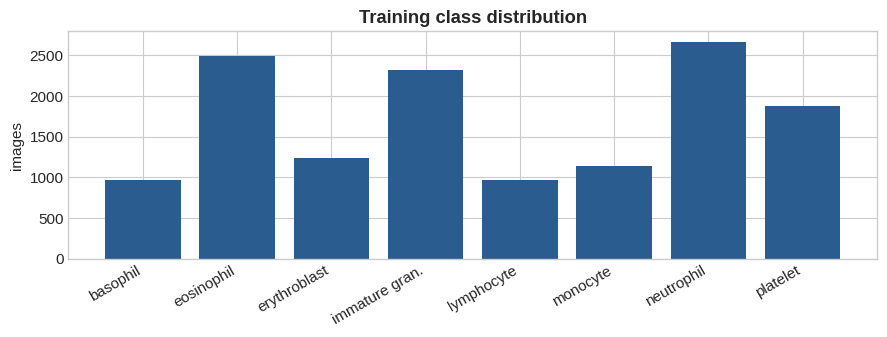

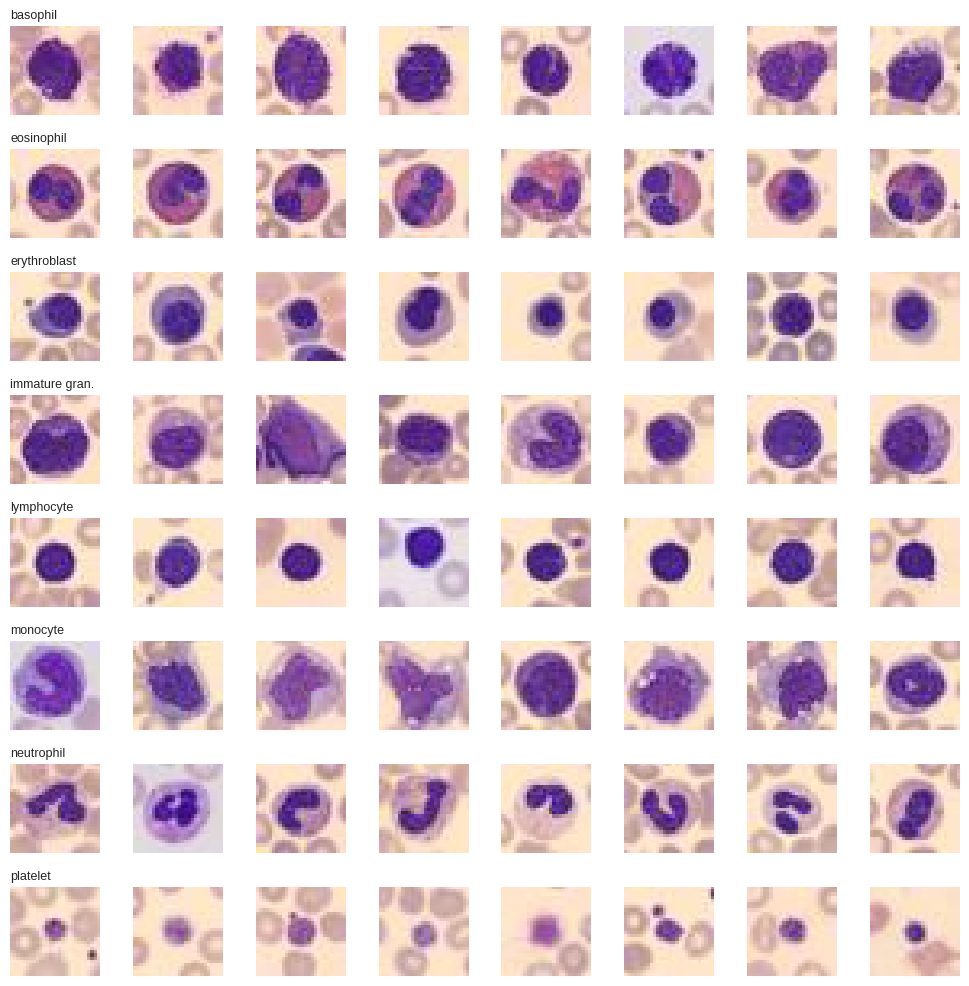

In [4]:
# Look at the data: class balance + a few samples per class
counts = np.bincount(y_all_np, minlength=NUM_CLASSES)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(NUM_CLASSES), counts, color='#2b5c8f')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_title("Training class distribution", fontweight='bold'); ax.set_ylabel("images")
plt.tight_layout(); plt.show()

rng = np.random.RandomState(0)
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(10, 10))
for c in range(NUM_CLASSES):
    idx = rng.choice(np.where(y_all_np == c)[0], 8, replace=False)
    for k, i in enumerate(idx):
        axes[c, k].imshow(X_all_np[i]); axes[c, k].axis('off')
    axes[c, 0].set_title(CLASS_NAMES[c], fontsize=9, loc='left')
plt.tight_layout(); plt.show()

## 4. Stratified Split, Normalization & Tensors
We hold out 10% of the labeled data (class proportions preserved) to select the best checkpoint and to measure honest accuracy. Per-channel mean/std are computed on the **training part only** (no leakage). All data is small, so it lives entirely on the compute device, which is much faster than a `DataLoader`.

In [5]:
def stratified_split(y, val_fraction, seed):
    rng = np.random.RandomState(seed)
    tr_idx, va_idx = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n_val = int(round(len(idx) * val_fraction))
        va_idx.extend(idx[:n_val]); tr_idx.extend(idx[n_val:])
    return np.array(sorted(tr_idx)), np.array(sorted(va_idx))

tr_idx, va_idx = stratified_split(y_all_np, CFG['val_fraction'], SEED)

def to_tensor(x_uint8):                       # (N,28,28,3) uint8 -> (N,3,28,28) float in [0,1]
    return torch.from_numpy(x_uint8).permute(0, 3, 1, 2).float() / 255.0

X_tr, X_va, X_te = to_tensor(X_all_np[tr_idx]), to_tensor(X_all_np[va_idx]), to_tensor(X_test_np)
y_tr, y_va = torch.from_numpy(y_all_np[tr_idx]), torch.from_numpy(y_all_np[va_idx])

MEAN = X_tr.mean(dim=(0, 2, 3), keepdim=True)
STD  = X_tr.std(dim=(0, 2, 3), keepdim=True)
norm = lambda x: (x - MEAN) / STD

X_tr, X_va, X_te = [norm(t).to(device) for t in (X_tr, X_va, X_te)]
y_tr, y_va = y_tr.to(device), y_va.to(device)

print(f"train: {tuple(X_tr.shape)}  val: {tuple(X_va.shape)}  test: {tuple(X_te.shape)}")
print("channel mean:", MEAN.flatten().tolist(), "std:", STD.flatten().tolist())

train: (12306, 3, 28, 28)  val: (1367, 3, 28, 28)  test: (3419, 3, 28, 28)
channel mean: [0.7944079637527466, 0.6597580313682556, 0.6962077021598816] std: [0.21553096175193787, 0.24147284030914307, 0.11795900017023087]


## 5. Data Augmentation (on-device)
Blood cells have **no canonical orientation**, so flips, 90° rotations (via transpose), small rotations, shifts and scale changes are all label-preserving. We also jitter brightness/contrast slightly because staining varies between slides. Augmentation is the main defence against overfitting on ~12k images, alongside Dropout and BatchNorm's mild noise.

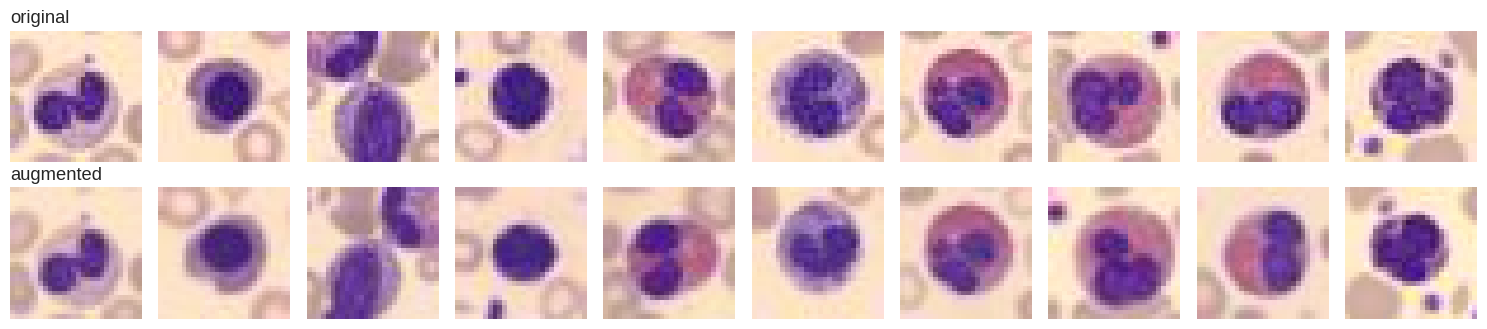

In [6]:
def augment(x):
    """Apply a light random transformation to each image batch.
    This keeps the model robust to flips, small rotations, and brightness changes.
    """
    B, dev = x.size(0), x.device

    # Random horizontal flip
    m = (torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1)
    x = torch.where(m, x.flip(3), x)

    # Random vertical flip
    m = (torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1)
    x = torch.where(m, x.flip(2), x)

    # Random transpose (90° rotation)
    m = (torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1)
    x = torch.where(m, x.transpose(2, 3), x)

    # Small affine transform: rotation, scale, and shift
    ang = (torch.rand(B, device=dev) * 2 - 1) * (18 * math.pi / 180)
    scale = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.08
    tx = (torch.rand(B, device=dev) * 2 - 1) * 0.08
    ty = (torch.rand(B, device=dev) * 2 - 1) * 0.08
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([
        torch.stack([cos, -sin, tx], dim=1),
        torch.stack([sin,  cos, ty], dim=1),
    ], dim=1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode='bilinear', padding_mode='reflection', align_corners=False)

    # Mild contrast and brightness adjustments
    contrast = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.12
    brightness = (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.08
    return x * contrast + brightness


def denorm(x):
    """Turn normalized image tensors back to RGB values for display."""
    return (x.cpu() * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).numpy()

# Visual check: originals (top) vs augmented versions (bottom)
sample = X_tr[:10]
aug = augment(sample)
fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for k in range(10):
    axes[0, k].imshow(denorm(sample)[k]); axes[0, k].axis('off')
    axes[1, k].imshow(denorm(aug)[k]);    axes[1, k].axis('off')
axes[0, 0].set_title("original", loc='left'); axes[1, 0].set_title("augmented", loc='left')
plt.tight_layout(); plt.show()


## 6. The Model: a BatchNorm CNN
Following Tutorial 2's modular blocks and Tutorial 3's rules, each conv block is
$$\text{Conv}_{3\times3}(\text{bias}=\text{False}) \rightarrow \text{BatchNorm2d} \rightarrow \text{ReLU}$$
Each **stage** stacks two such blocks (more depth per resolution than Tutorial 2's single conv), then `MaxPool2d(2)`:

`28x28 -> 14x14 -> 7x7 -> 3x3`, with channels `48 -> 96 -> 192`.

The head uses **Global Average Pooling** (Tutorial 2, Method B) so there is no giant `Flatten -> Linear`, then a small dense layer with BatchNorm1d and our own **`CustomDropout`** from Tutorial 4 (placed *after* the ReLU, as the tutorial recommends).

In [7]:
class CustomDropout(nn.Module):
    """A simple dropout layer that keeps the same output scale during training."""
    def __init__(self, p: float = 0.5):
        super().__init__()
        if not (0.0 <= p < 1.0):
            raise ValueError(f"Dropout probability p must be in [0, 1), got {p}")
        self.p = float(p)

    def forward(self, x):
        # During training: randomly zero some values and scale up to keep expectation same.
        if not self.training or self.p == 0.0:
            return x
        mask = (torch.rand_like(x) >= self.p).to(x.dtype)
        return (x * mask) / (1.0 - self.p)

    def extra_repr(self):
        return f"p={self.p}"


class ConvBlock(nn.Sequential):
    """Conv -> BatchNorm -> ReLU"""
    def __init__(self, in_ch, out_ch):
        super().__init__(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )


class Stage(nn.Module):
    """Two conv blocks, then downsample by 2x."""
    def __init__(self, in_ch, out_ch, drop=0.0):
        super().__init__()
        self.block = nn.Sequential(
            ConvBlock(in_ch, out_ch),
            ConvBlock(out_ch, out_ch),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(drop) if drop > 0 else nn.Identity(),
        )

    def forward(self, x):
        return self.block(x)


class BloodCNN(nn.Module):
    """A simple CNN designed for 28x28 RGB blood-cell images."""
    def __init__(self, num_classes=8, widths=(48, 96, 192), conv_drop=0.1, head_drop=0.4):
        super().__init__()
        w1, w2, w3 = widths
        self.stage1 = Stage(3,  w1, conv_drop)
        self.stage2 = Stage(w1, w2, conv_drop)
        self.stage3 = Stage(w2, w3, conv_drop)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(w3, 256, bias=False),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            CustomDropout(head_drop),
            nn.Linear(256, num_classes),
        )

        # He initialization is good for ReLU networks and helps convergence.
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        return self.head(x)


def build_model():
    return BloodCNN(NUM_CLASSES, CFG['widths'], CFG['conv_drop'], CFG['head_drop']).to(device)

model = build_model()
n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_params:,}")

# Quick shape check to confirm the architecture works as intended.
x = torch.randn(2, 3, 28, 28, device=device)
print("input:", tuple(x.shape))
for name in ['stage1', 'stage2', 'stage3']:
    x = getattr(model, name)(x)
    print(f"after {name}:", tuple(x.shape))
print("logits:", tuple(model.head(x).shape))


Trainable parameters: 1,214,408
input: (2, 3, 28, 28)
after stage1: (2, 64, 14, 14)
after stage2: (2, 128, 7, 7)
after stage3: (2, 256, 3, 3)
logits: (2, 8)


## 7. Training & Evaluation Utilities
Same structure as Tutorials 2-3 (`zero_grad -> forward -> loss -> backward -> step`), with:
- **AdamW** + **OneCycleLR** (warm-up to a high LR, then cosine-anneal to ~0; BatchNorm makes the high peak LR safe),
- **label smoothing** to reduce over-confidence,
- `model.train()` / `model.eval()` toggled correctly so BatchNorm uses batch stats while training and running stats at evaluation, and Dropout is only active in training.

In [8]:
def iterate(X, y, bs, shuffle):
    """Yield mini-batches from the data. If shuffle=True, the order changes each epoch."""
    n = X.size(0)
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, bs):
        j = idx[i:i + bs]
        if shuffle and j.numel() < 2:
            continue
        yield X[j], y[j]


def train_one_epoch(model, X, y, criterion, optimizer, scheduler=None, use_aug=True, bs=128):
    """Train for one full pass over the training set."""
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for xb, yb in iterate(X, y, bs, shuffle=True):
        if use_aug:
            xb = augment(xb)

        optimizer.zero_grad(set_to_none=True)
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()

        if scheduler is not None:
            scheduler.step()

        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += yb.size(0)

    return running_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(model, X, y, criterion, bs=512):
    """Measure loss and accuracy without updating weights."""
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    for xb, yb in iterate(X, y, bs, shuffle=False):
        out = model(xb)
        running_loss += criterion(out, yb).item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += yb.size(0)

    return running_loss / total, 100.0 * correct / total


## 8. Sanity Check: Can the Model Overfit a Tiny Subset? (Tutorial 2, Section 6)
Before spending time on full training, confirm the pipeline has no bugs: with no augmentation, the network should memorize 64 images (training accuracy close to 100%).

In [9]:
seed_everything(SEED)
sanity_model = build_model()
sub_idx = torch.randperm(X_tr.size(0), device=device)[:64]
Xs, ys = X_tr[sub_idx], y_tr[sub_idx]
crit_plain = nn.CrossEntropyLoss()
opt = optim.Adam(sanity_model.parameters(), lr=2e-3)
for ep in range(1, 61):
    tl, ta = train_one_epoch(sanity_model, Xs, ys, crit_plain, opt, use_aug=False, bs=32)
    if ep % 15 == 0:
        el, ea = evaluate(sanity_model, Xs, ys, crit_plain)
        print(f"epoch {ep:2d} | train loss {tl:.4f} | eval-mode acc on the 64 images: {ea:.1f}%")
print("PASS: pipeline can memorize a tiny subset." if ea >= 95 else "WARNING: could not overfit 64 images, check the pipeline!")
del sanity_model, opt

epoch 15 | train loss 0.2128 | eval-mode acc on the 64 images: 90.6%
epoch 30 | train loss 0.0539 | eval-mode acc on the 64 images: 100.0%
epoch 45 | train loss 0.0186 | eval-mode acc on the 64 images: 96.9%
epoch 60 | train loss 0.0945 | eval-mode acc on the 64 images: 95.3%
PASS: pipeline can memorize a tiny subset.


## 9. Train the Model(s)
Each run keeps the **checkpoint with the best validation accuracy** (ties broken by lower validation loss). We train `n_models` networks with different seeds on the same split and ensemble them later; this typically adds a solid boost over a single model.

In [10]:
def fit(seed, verbose=True):
    """Train one model and keep the best validation checkpoint."""
    seed_everything(seed)
    model = build_model()

    # Training loss uses label smoothing; validation uses standard cross-entropy for reporting.
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smooth'])
    eval_criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(model.parameters(), lr=CFG['max_lr'], weight_decay=CFG['weight_decay'])
    steps_per_epoch = math.ceil(X_tr.size(0) / CFG['batch_size'])
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=CFG['max_lr'],
        epochs=CFG['epochs'],
        steps_per_epoch=steps_per_epoch,
        pct_start=0.2,
    )

    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best = dict(acc=-1.0, loss=1e9, state=None, epoch=0)
    t0 = time.time()

    for ep in range(1, CFG['epochs'] + 1):
        tl, ta = train_one_epoch(model, X_tr, y_tr, criterion, optimizer, scheduler, True, CFG['batch_size'])
        vl, va = evaluate(model, X_va, y_va, eval_criterion)

        for k, v in zip(hist, (tl, ta, vl, va)):
            hist[k].append(v)

        # Save the best weights by validation accuracy, then by lower loss.
        if va > best['acc'] or (va == best['acc'] and vl < best['loss']):
            best.update(acc=va, loss=vl, epoch=ep, state=copy.deepcopy(model.state_dict()))

        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"[seed {seed}] epoch {ep:2d}/{CFG['epochs']} | "
                  f"train loss {tl:.4f} acc {ta:5.2f}% | "
                  f"val loss {vl:.4f} acc {va:5.2f}% | {time.time() - t0:.0f}s")

    model.load_state_dict(best['state'])
    print(f"[seed {seed}] best val acc {best['acc']:.2f}% at epoch {best['epoch']}")
    return model, hist, best


models, histories = [], []
for k in range(CFG['n_models']):
    m, h, b = fit(SEED + k)
    torch.save(m.state_dict(), f"best_model_{k}.pt")
    models.append(m)
    histories.append(h)


[seed 42] epoch  1/50 | train loss 1.0440 acc 68.63% | val loss 0.5129 acc 84.56% | 3s
[seed 42] epoch  5/50 | train loss 0.5614 acc 88.65% | val loss 0.4255 acc 85.00% | 13s
[seed 42] epoch 10/50 | train loss 0.4880 acc 91.88% | val loss 0.2707 acc 91.22% | 25s
[seed 42] epoch 15/50 | train loss 0.4397 acc 93.85% | val loss 0.2476 acc 92.10% | 38s
[seed 42] epoch 20/50 | train loss 0.4126 acc 94.72% | val loss 0.2807 acc 91.73% | 51s
[seed 42] epoch 25/50 | train loss 0.3926 acc 95.56% | val loss 0.1819 acc 94.95% | 64s
[seed 42] epoch 30/50 | train loss 0.3772 acc 96.34% | val loss 0.2552 acc 91.88% | 78s
[seed 42] epoch 35/50 | train loss 0.3559 acc 96.94% | val loss 0.1763 acc 95.32% | 91s
[seed 42] epoch 40/50 | train loss 0.3420 acc 97.59% | val loss 0.1591 acc 95.76% | 105s
[seed 42] epoch 45/50 | train loss 0.3336 acc 97.94% | val loss 0.1525 acc 96.42% | 119s
[seed 42] epoch 50/50 | train loss 0.3270 acc 98.04% | val loss 0.1617 acc 96.05% | 133s
[seed 42] best val acc 96.42% 

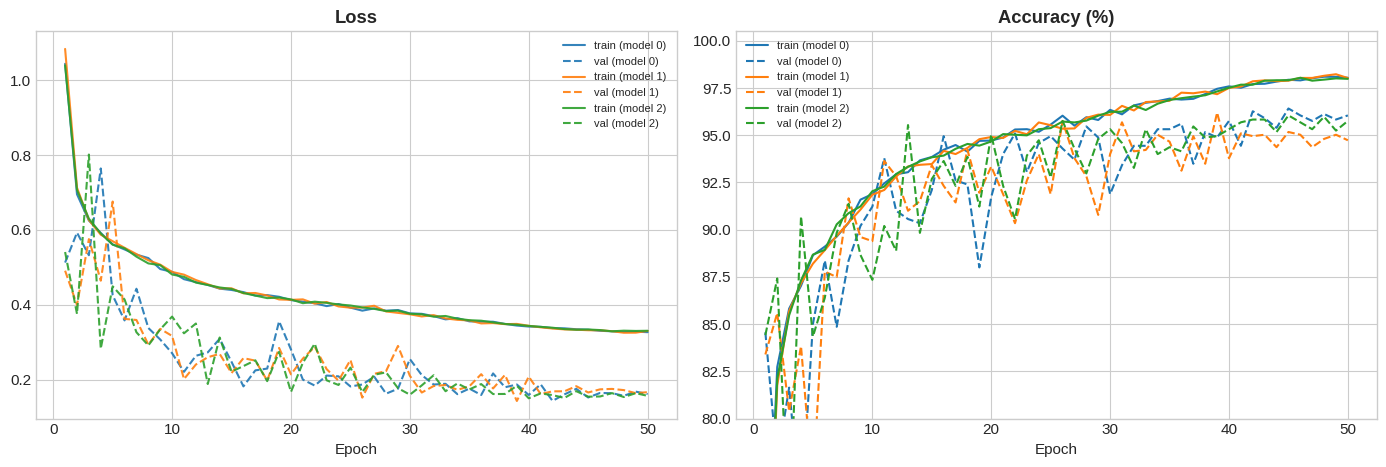

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ep_range = range(1, CFG['epochs'] + 1)
for k, h in enumerate(histories):
    axes[0].plot(ep_range, h['train_loss'], '-',  color=f'C{k}', alpha=.9, label=f'train (model {k})')
    axes[0].plot(ep_range, h['val_loss'],   '--', color=f'C{k}', alpha=.9, label=f'val (model {k})')
    axes[1].plot(ep_range, h['train_acc'], '-',  color=f'C{k}', label=f'train (model {k})')
    axes[1].plot(ep_range, h['val_acc'],   '--', color=f'C{k}', label=f'val (model {k})')
axes[0].set_title("Loss", fontweight='bold'); axes[0].set_xlabel("Epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("Accuracy (%)", fontweight='bold'); axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8)
axes[1].set_ylim(80, 100.5)
plt.tight_layout(); plt.show()

## 10. Ensemble + Test-Time Augmentation (TTA)
For each image we average the softmax probabilities over all **8 flips/rotations** (the dihedral group the model was trained with) and over every model in the ensemble. Everything runs in `model.eval()` so BatchNorm uses its running statistics and Dropout is off.

In [12]:
@torch.no_grad()
def predict_proba(model, X, tta=True, bs=512):
    model.eval()
    outs = []
    for i in range(0, X.size(0), bs):
        xb = X[i:i + bs]
        variants = [xb]
        if tta:
            variants = []
            for tr in (False, True):
                base = xb.transpose(2, 3) if tr else xb
                for fh in (False, True):
                    for fv in (False, True):
                        v = base
                        if fh: v = v.flip(3)
                        if fv: v = v.flip(2)
                        variants.append(v)
        probs = torch.stack([F.softmax(model(v), dim=1) for v in variants]).mean(0)
        outs.append(probs)
    return torch.cat(outs)

val_probs_each = [predict_proba(m, X_va, tta=True) for m in models]
for k, p in enumerate(val_probs_each):
    print(f"model {k}: val acc with TTA = {100 * (p.argmax(1) == y_va).float().mean().item():.2f}%")
val_probs = torch.stack(val_probs_each).mean(0)
val_preds = val_probs.argmax(1)
ens_acc = 100 * (val_preds == y_va).float().mean().item()
print(f"\nENSEMBLE ({len(models)} models) + TTA validation accuracy: {ens_acc:.2f}%")

model 0: val acc with TTA = 96.56%
model 1: val acc with TTA = 96.63%
model 2: val acc with TTA = 95.68%

ENSEMBLE (3 models) + TTA validation accuracy: 96.34%


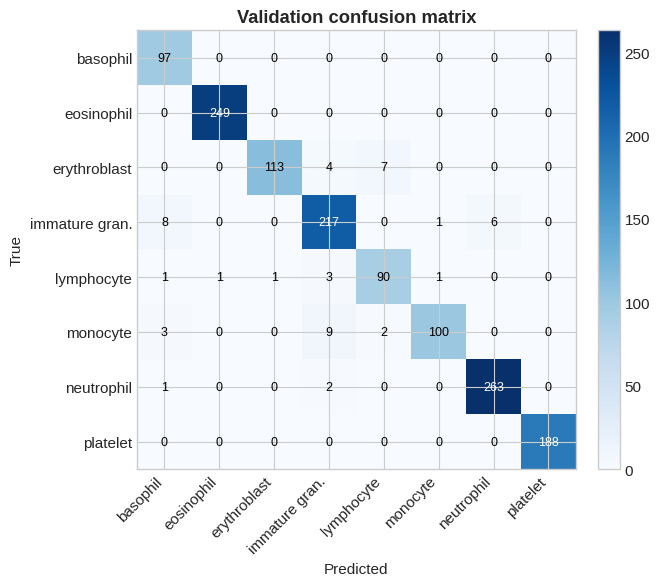

        basophil: 100.0%  (97 val images)
      eosinophil: 100.0%  (249 val images)
    erythroblast:  91.1%  (124 val images)
  immature gran.:  93.5%  (232 val images)
      lymphocyte:  92.8%  (97 val images)
        monocyte:  87.7%  (114 val images)
      neutrophil:  98.9%  (266 val images)
        platelet: 100.0%  (188 val images)


In [13]:
# Confusion matrix & per-class accuracy on the validation split
yt, yp = y_va.cpu().numpy(), val_preds.cpu().numpy()
cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
for t, p in zip(yt, yp):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right'); ax.set_yticklabels(CLASS_NAMES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Validation confusion matrix", fontweight='bold')
plt.colorbar(im, fraction=0.046, pad=0.04); plt.tight_layout(); plt.show()

for c in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[c]:>16s}: {100 * cm[c, c] / max(cm[c].sum(), 1):5.1f}%  ({cm[c].sum()} val images)")

## 11. Create the Kaggle Submission
Predictions are written in exactly the order and column names of `sample_submission.csv`.

In [14]:
test_probs = torch.stack([predict_proba(m, X_te, tta=True) for m in models]).mean(0)
test_preds = test_probs.argmax(1).cpu().numpy()

submission = sample_df.copy()
submission[submission.columns[1]] = test_preds.astype(int)
submission.to_csv("submission.csv", index=False)

# Format checks
assert len(submission) == len(sample_df) == X_te.size(0)
assert list(submission.columns) == list(sample_df.columns)
assert (submission[submission.columns[0]].values == sample_df[sample_df.columns[0]].values).all()
print("Saved submission.csv", submission.shape)
print("Predicted class distribution:", np.bincount(test_preds, minlength=NUM_CLASSES).tolist())
submission.head()

Saved submission.csv (3419, 2)
Predicted class distribution: [271, 624, 299, 595, 240, 252, 668, 470]


,image_id,label
0,32630ef937.png,3
1,136affd755.png,5
2,391203af62.png,1
3,78bfaa91c3.png,0
4,1a47dc97ba.png,0


## 12. Summary

| Design choice | Why (tutorial link) |
| :--- | :--- |
| `Conv(bias=False) -> BatchNorm -> ReLU` | Stable activations, no saturation/vanishing gradients, redundant bias removed (T3) |
| High peak LR with OneCycle + AdamW | BatchNorm tolerates large learning rates and converges fast (T3) |
| Global Average Pooling head | Far fewer parameters than `Flatten -> Linear` (T2) |
| Light `Dropout2d` in conv, `CustomDropout(0.4)` in dense head | Regularization where it helps most, after the activation (T4) |
| Flip/rotation/affine/contrast augmentation | Cells have no canonical orientation, so these are label-preserving |
| Tiny-subset overfit test | Verifies the pipeline before full training (T2) |
| `model.eval()` for validation/test, best-val checkpoint | BatchNorm running stats + Dropout off at inference (T3, T4) |
| Seed ensemble + 8-way TTA | Cheap variance reduction at inference time |

**Reproducibility:** all seeds are fixed (`SEED = 42`), the split is deterministic, and no external or pretrained weights are used. Re-running top-to-bottom regenerates `submission.csv`.